<a href="https://colab.research.google.com/github/balajirao304-ship-it/Qiskit-Fall-Fest-2026-IIITKottayam-Hackathon-Template/blob/main/performance_of_petrol_engine_by_qml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 124.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 126.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 111.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 7.1 MB/s eta 0:00:00
Brake Power: 0.9 kW
Normalized BP: 0.6
Rotation angle: 1.8849555921538759 radians

Quantum circuit:
     ┌──────────┐┌─┐
  q: ┤ Ry(3π/5) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 

Measurement counts:
{'0': 714, '1': 1334}
Probability of 0: 0.3486328125
Probability of 1: 0.6513671875


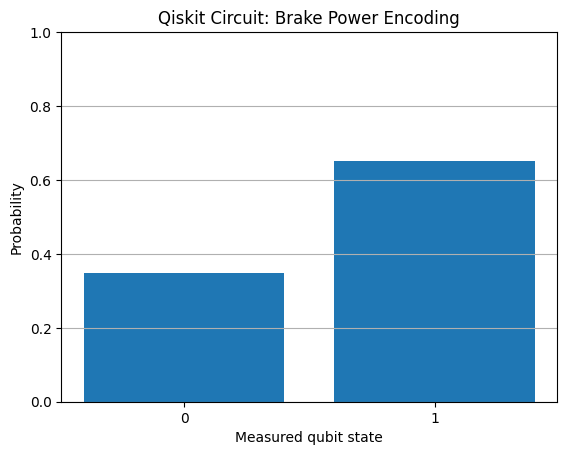

In [ ]:
!pip install -q qiskit qiskit-aer

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# =====================================
# Engine experimental data
# =====================================

voltage = 200
current = np.array([0, 1.5, 2.5, 3.0, 4.0,
                    4.5, 6.0, 7.0, 7.5])

time = np.array([39.34, 38.75, 38.35, 33.24,
                 29.20, 29.20, 20.90, 21.07, 16.70])

# Brake power in kW
brake_power = voltage * current / 1000

# =====================================
# Select one operating point
# =====================================

index = 5
bp = brake_power[index]

# Normalize brake power to [0, 1]
bp_norm = bp / brake_power.max()

# Convert normalized value to a rotation angle
theta = np.pi * bp_norm

print("Brake Power:", bp, "kW")
print("Normalized BP:", bp_norm)
print("Rotation angle:", theta, "radians")

# =====================================
# Create a one-qubit quantum circuit
# =====================================

qc = QuantumCircuit(1, 1)

# Encode brake power using a Y rotation
qc.ry(theta, 0)

# Measure the qubit
qc.measure(0, 0)

print("\nQuantum circuit:")
print(qc.draw(output="text"))

# =====================================
# Simulate the circuit
# =====================================

simulator = AerSimulator()

compiled_circuit = transpile(qc, simulator)

result = simulator.run(
    compiled_circuit,
    shots=2048
).result()

counts = result.get_counts()

print("\nMeasurement counts:")
print(counts)

# =====================================
# Plot measurement probabilities
# =====================================

total_shots = sum(counts.values())

p0 = counts.get("0", 0) / total_shots
p1 = counts.get("1", 0) / total_shots

print("Probability of 0:", p0)
print("Probability of 1:", p1)

plt.bar(["0", "1"], [p0, p1])
plt.xlabel("Measured qubit state")
plt.ylabel("Probability")
plt.title("Qiskit Circuit: Brake Power Encoding")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00

ENGINE DATA
   Brake Power  Fuel Consumption     SFC  Brake Thermal Efficiency  \
0          0.3            0.6875  2.2916                    3.5703   
1          0.5            0.6947  1.3893                    5.8891   
2          0.6            0.8014  1.3357                    6.1253   
3          0.8            0.9123  1.1404                    7.1744   
4          0.9            0.9123  1.0137                    8.0713   
5          1.2            1.2746  1.0622                    7.7027   
6          1.4            1.2644  0.9031                    9.0596   
7          1.5            1.5952  

/tmp/ipykernel_1549/675869013.py:148: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1549/675869013.py:153: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


Classical Quadratic    | R2= 0.5696 | MAE=0.1758 | RMSE=0.1805
Quantum VQR            | R2=-3.1508 | MAE=0.4878 | RMSE=0.5605

TARGET: SFC
Classical Quadratic    | R2= 0.7790 | MAE=0.2189 | RMSE=0.2444
Quantum VQR            | R2=-0.7584 | MAE=0.5016 | RMSE=0.6894

TARGET: Brake Thermal Efficiency
Classical Quadratic    | R2= 0.5955 | MAE=1.0729 | RMSE=1.0757
Quantum VQR            | R2=-2.0352 | MAE=2.6498 | RMSE=2.9465

TARGET: Indicated Thermal Efficiency
Classical Quadratic    | R2=-1.8692 | MAE=1.5989 | RMSE=1.6000
Quantum VQR            | R2=-2.2811 | MAE=1.2321 | RMSE=1.7110

TARGET: Mechanical Efficiency
Classical Quadratic    | R2= 0.9587 | MAE=1.9707 | RMSE=2.7549
Quantum VQR            | R2=-1.3309 | MAE=19.8411 | RMSE=20.6906


FINAL MODEL COMPARISON
                   Parameter               Model  Test R2  Test MAE  Test RMSE
            Fuel Consumption Classical Quadratic   0.5696    0.1758     0.1805
            Fuel Consumption         Quantum VQR  -3.1508    0.4878  

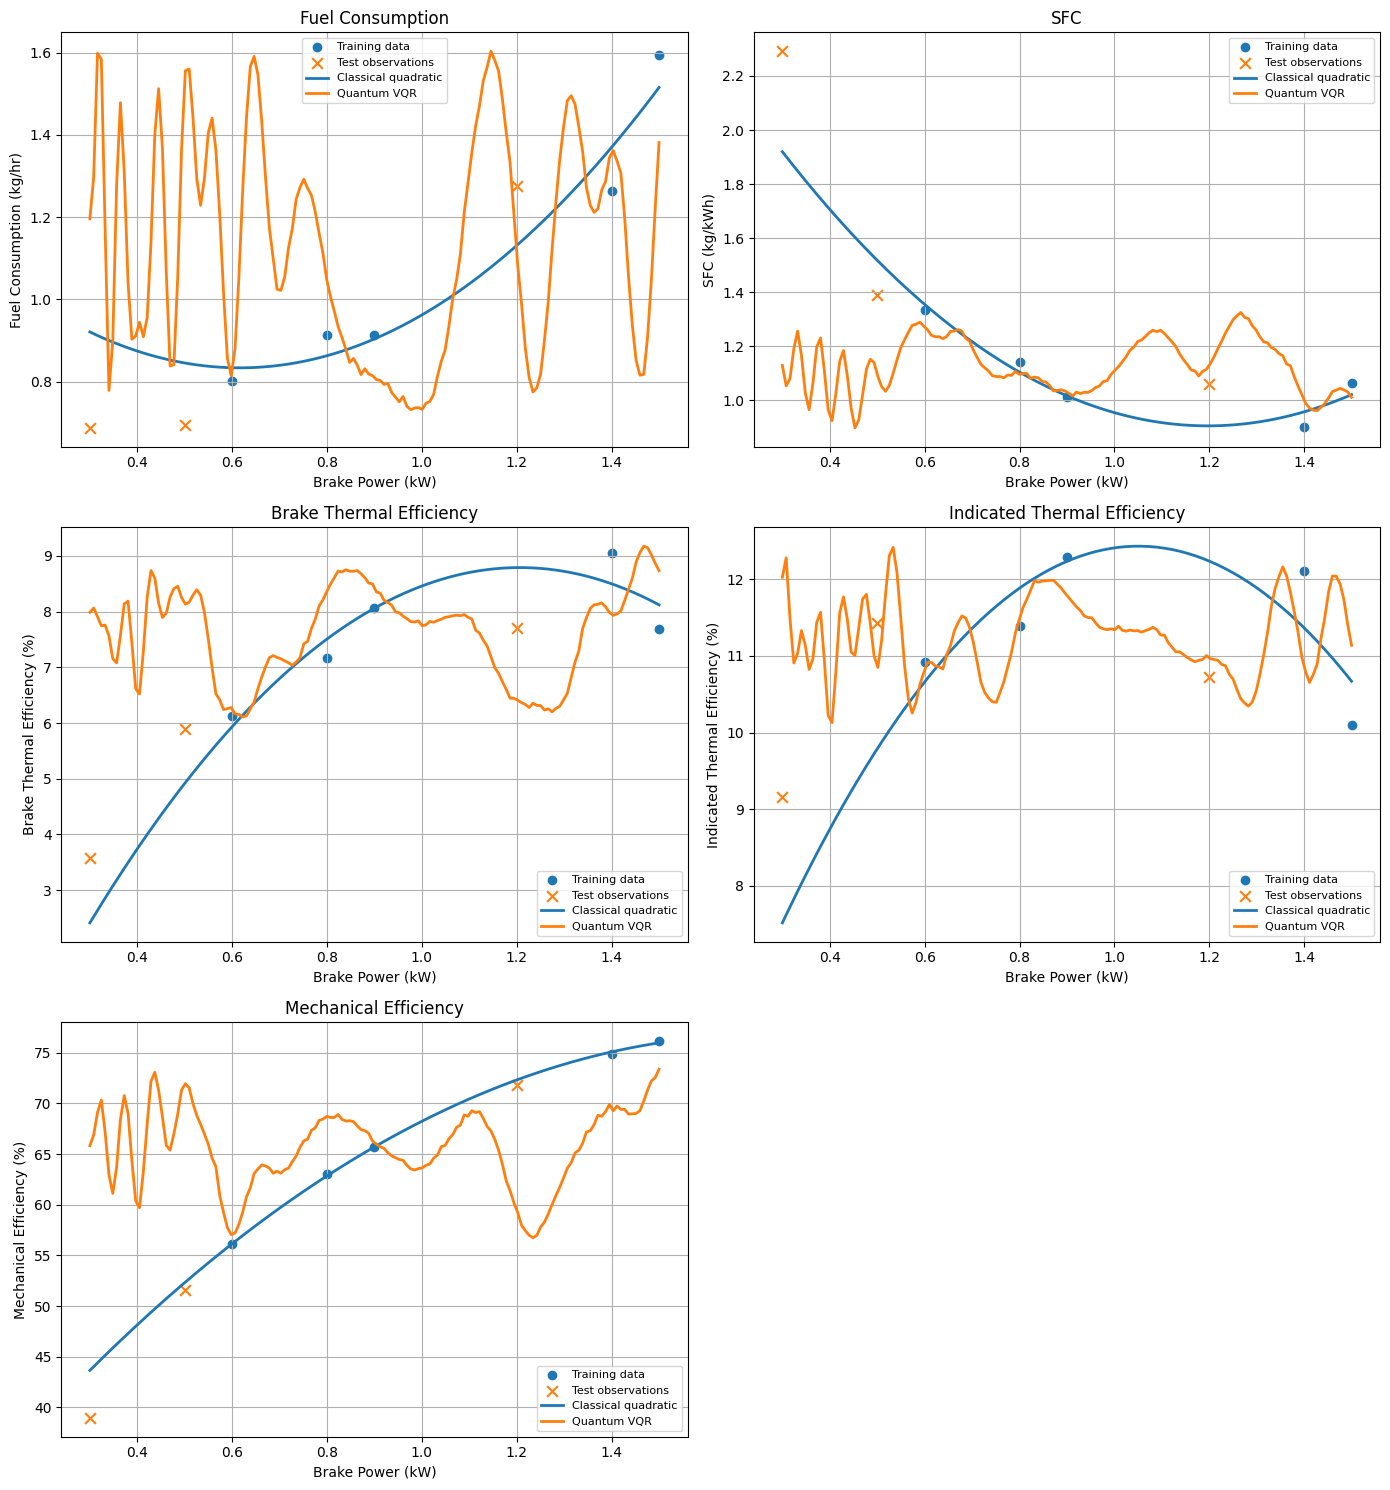

In [2]:
!pip install -q qiskit qiskit-machine-learning qiskit-algorithms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms import VQR

# =====================================================
# 1. ORIGINAL ENGINE EXPERIMENTAL DATA
# =====================================================

voltage = np.array([200] * 9, dtype=float)

current = np.array([
    0, 1.5, 2.5, 3.0, 4.0, 4.5, 6.0, 7.0, 7.5
], dtype=float)

time = np.array([
    39.34, 38.75, 38.35, 33.24, 29.20,
    29.20, 20.90, 21.07, 16.70
], dtype=float)

# =====================================================
# 2. ENGINE CONSTANTS
# =====================================================

FP = 0.47             # Friction power (kW)
density = 0.74        # Fuel density (kg/L)
fuel_volume = 10      # Fuel volume (mL)
CV = 44000            # Calorific value (kJ/kg)

fuel_mass = (fuel_volume / 1000) * density

# =====================================================
# 3. CALCULATE ENGINE PERFORMANCE PARAMETERS
# =====================================================

df = pd.DataFrame({
    "Voltage": voltage,
    "Current": current,
    "Time": time
})

# Preserving the brake-power formula from your program
df["Brake Power"] = (
    df["Voltage"] * df["Current"] / 1000
)

df["Fuel Consumption"] = (
    fuel_mass * 3600 / df["Time"]
)

fuel_rate = df["Fuel Consumption"] / 3600

df["SFC"] = (
    df["Fuel Consumption"] / df["Brake Power"]
)

df["Indicated Power"] = df["Brake Power"] + FP

df["Brake Thermal Efficiency"] = (
    df["Brake Power"] / (fuel_rate * CV) * 100
)

df["Indicated Thermal Efficiency"] = (
    df["Indicated Power"] / (fuel_rate * CV) * 100
)

df["Mechanical Efficiency"] = (
    df["Brake Power"] / df["Indicated Power"] * 100
)

# SFC is undefined at zero brake power.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Use the same positive-brake-power observations
# for a fair comparison across all five targets.
df = df[df["Brake Power"] > 0].copy()
df.reset_index(drop=True, inplace=True)

targets = {
    "Fuel Consumption": "Fuel Consumption (kg/hr)",
    "SFC": "SFC (kg/kWh)",
    "Brake Thermal Efficiency": "Brake Thermal Efficiency (%)",
    "Indicated Thermal Efficiency": "Indicated Thermal Efficiency (%)",
    "Mechanical Efficiency": "Mechanical Efficiency (%)"
}

print("\nENGINE DATA")
print(df[["Brake Power"] + list(targets.keys())].round(4))

# =====================================================
# 4. TRAIN / TEST SPLIT
# =====================================================

# Three test observations and five training observations.
# This small test set is for demonstration, not a
# statistically reliable performance estimate.

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=3,
    random_state=42
)

bp = df["Brake Power"].to_numpy().reshape(-1, 1)

bp_train = bp[train_idx]
bp_test = bp[test_idx]

# =====================================================
# 5. QUANTUM INPUT FEATURES
# =====================================================

# Scale brake power to approximately [-1, 1].
# Add a nonlinear feature to represent curvature.

x_scaler = MinMaxScaler(feature_range=(-1, 1))

x_train_1d = x_scaler.fit_transform(bp_train).ravel()
x_test_1d = x_scaler.transform(bp_test).ravel()

def quantum_features(x):
    x = np.asarray(x).reshape(-1)
    return np.column_stack([
        x,
        2 * x**2 - 1
    ])

Xq_train = quantum_features(x_train_1d)
Xq_test = quantum_features(x_test_1d)

# =====================================================
# 6. QUANTUM CIRCUIT AND VQR CONFIGURATION
# =====================================================

feature_map = ZZFeatureMap(
    feature_dimension=2,
    reps=1
)

ansatz = RealAmplitudes(
    num_qubits=2,
    reps=1
)

estimator = StatevectorEstimator()

# =====================================================
# 7. FIT BOTH MODELS FOR ALL FIVE TARGETS
# =====================================================

results = []
predictions = {}

for target, ylabel in targets.items():

    print("\n" + "=" * 65)
    print("TARGET:", target)
    print("=" * 65)

    y = df[target].to_numpy()

    y_train = y[train_idx]
    y_test = y[test_idx]

    # -------------------------------------------------
    # A. CLASSICAL QUADRATIC REGRESSION
    # -------------------------------------------------

    poly = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(bp_train)
    X_test_poly = poly.transform(bp_test)

    classical_model = LinearRegression()
    classical_model.fit(X_train_poly, y_train)

    pred_classical = classical_model.predict(X_test_poly)

    # -------------------------------------------------
    # B. SCALE TARGET FOR QUANTUM REGRESSION
    # -------------------------------------------------

    y_scaler = MinMaxScaler(
        feature_range=(-0.8, 0.8)
    )

    y_train_scaled = y_scaler.fit_transform(
        y_train.reshape(-1, 1)
    ).ravel()

    # -------------------------------------------------
    # C. VARIATIONAL QUANTUM REGRESSOR
    # -------------------------------------------------

    quantum_model = VQR(
        feature_map=feature_map,
        ansatz=ansatz,
        optimizer=COBYLA(maxiter=40),
        estimator=estimator
    )

    quantum_model.fit(
        Xq_train,
        y_train_scaled
    )

    pred_quantum_scaled = np.asarray(
        quantum_model.predict(Xq_test)
    ).reshape(-1, 1)

    pred_quantum = y_scaler.inverse_transform(
        pred_quantum_scaled
    ).ravel()

    # -------------------------------------------------
    # D. EVALUATE TEST PREDICTIONS
    # -------------------------------------------------

    for model_name, pred in [
        ("Classical Quadratic", pred_classical),
        ("Quantum VQR", pred_quantum)
    ]:

        r2 = r2_score(y_test, pred)
        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))

        results.append({
            "Parameter": target,
            "Model": model_name,
            "Test R2": r2,
            "Test MAE": mae,
            "Test RMSE": rmse
        })

        print(
            f"{model_name:22s} | "
            f"R2={r2: .4f} | "
            f"MAE={mae:.4f} | "
            f"RMSE={rmse:.4f}"
        )

    # Save predictions for comparison table and plots.
    predictions[target] = {
        "actual": y_test,
        "classical": pred_classical,
        "quantum": pred_quantum,
        "bp_test": bp_test.ravel(),
        "classical_model": classical_model,
        "quantum_model": quantum_model,
        "y_scaler": y_scaler
    }

# =====================================================
# 8. COMPARISON TABLE
# =====================================================

results_df = pd.DataFrame(results)

print("\n\nFINAL MODEL COMPARISON")
print(
    results_df.round(4).to_string(index=False)
)

results_df.to_csv(
    "quantum_vs_classical_metrics.csv",
    index=False
)

# =====================================================
# 9. ACTUAL VS PREDICTED TEST VALUES
# =====================================================

for target in targets:

    p = predictions[target]

    comparison = pd.DataFrame({
        "Brake Power (kW)": p["bp_test"],
        "Actual": p["actual"],
        "Classical Prediction": p["classical"],
        "Quantum Prediction": p["quantum"]
    })

    print(f"\nTEST PREDICTIONS: {target}")
    print(comparison.round(4).to_string(index=False))

# =====================================================
# 10. PLOT FIVE PERFORMANCE CURVES
# =====================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 15)
)

axes = axes.ravel()

bp_grid = np.linspace(
    bp.min(),
    bp.max(),
    150
).reshape(-1, 1)

bp_grid_1d = x_scaler.transform(bp_grid).ravel()
Xq_grid = quantum_features(bp_grid_1d)

for i, (target, ylabel) in enumerate(targets.items()):

    ax = axes[i]
    p = predictions[target]

    # Classical predictions across the full range
    poly = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    # Fit transform is unnecessary here: the polynomial
    # basis has the same two columns used in training.
    X_grid_poly = np.column_stack([
        bp_grid.ravel(),
        bp_grid.ravel()**2
    ])

    classical_curve = p["classical_model"].predict(
        X_grid_poly
    )

    # Quantum predictions across the full range
    quantum_curve_scaled = np.asarray(
        p["quantum_model"].predict(Xq_grid)
    ).reshape(-1, 1)

    quantum_curve = p["y_scaler"].inverse_transform(
        quantum_curve_scaled
    ).ravel()

    ax.scatter(
        bp[train_idx].ravel(),
        df[target].to_numpy()[train_idx],
        label="Training data",
        marker="o"
    )

    ax.scatter(
        p["bp_test"],
        p["actual"],
        label="Test observations",
        marker="x",
        s=60
    )

    ax.plot(
        bp_grid.ravel(),
        classical_curve,
        label="Classical quadratic",
        linewidth=2
    )

    ax.plot(
        bp_grid.ravel(),
        quantum_curve,
        label="Quantum VQR",
        linewidth=2
    )

    ax.set_xlabel("Brake Power (kW)")
    ax.set_ylabel(ylabel)
    ax.set_title(target)
    ax.grid(True)
    ax.legend(fontsize=8)

# Remove the unused sixth subplot.
fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig(
    "quantum_vs_classical_engine_curves.png",
    dpi=300
)
plt.show()



ORIGINAL PERFORMANCE DATA
 Brake Power  Fuel Consumption    SFC  Brake Thermal Efficiency  Indicated Thermal Efficiency  Mechanical Efficiency
         0.3            0.6875 2.2916                    3.5703                        9.1639                38.9610
         0.5            0.6947 1.3893                    5.8891                       11.4249                51.5464
         0.6            0.8014 1.3357                    6.1253                       10.9235                56.0748
         0.8            0.9123 1.1404                    7.1744                       11.3894                62.9921
         0.9            0.9123 1.0137                    8.0713                       12.2862                65.6934
         1.2            1.2746 1.0622                    7.7027                       10.7196                71.8563
         1.4            1.2644 0.9031                    9.0596                       12.1010                74.8663
         1.5            1.5952 1.0635

/tmp/ipykernel_1549/2632585065.py:225: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1549/2632585065.py:230: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


Classical Quadratic    | R2 = 0.5696 | MAE = 0.1758 | RMSE = 0.1805
Quantum VQR            | R2 = -0.6877 | MAE = 0.2847 | RMSE = 0.3574

PERFORMANCE PARAMETER: SFC
Classical equation: y = 2.711430 + (-3.016400) BP + (1.259894) BP^2


/tmp/ipykernel_1549/2632585065.py:225: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1549/2632585065.py:230: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


Classical Quadratic    | R2 = 0.7790 | MAE = 0.2189 | RMSE = 0.2444
Quantum VQR            | R2 = -0.9425 | MAE = 0.5332 | RMSE = 0.7246

PERFORMANCE PARAMETER: Brake Thermal Efficiency
Classical equation: y = -2.509039 + (18.731552) BP + (-7.763255) BP^2


...

Classical Quadratic    | R2 = 0.5955 | MAE = 1.0729 | RMSE = 1.0757
Quantum VQR            | R2 = -1.8450 | MAE = 2.4225 | RMSE = 2.8526

PERFORMANCE PARAMETER: Indicated Thermal Efficiency
Classical equation: y = 2.810455 + (18.310563) BP + (-8.714773) BP^2


/tmp/ipykernel_1549/2632585065.py:225: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1549/2632585065.py:230: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


Classical Quadratic    | R2 = -1.8692 | MAE = 1.5989 | RMSE = 1.6000
Quantum VQR            | R2 = -1.7229 | MAE = 1.1362 | RMSE = 1.5587

PERFORMANCE PARAMETER: Mechanical Efficiency
Classical equation: y = 28.197391 + (56.416338) BP + (-16.375939) BP^2


/tmp/ipykernel_1549/2632585065.py:225: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1549/2632585065.py:230: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


Classical Quadratic    | R2 = 0.9587 | MAE = 1.9707 | RMSE = 2.7549
Quantum VQR            | R2 = -1.3684 | MAE = 20.4436 | RMSE = 20.8566

FINAL TEST-SET COMPARISON
                   Parameter               Model  Test R2  Test MAE  Test RMSE
            Fuel Consumption Classical Quadratic   0.5696    0.1758     0.1805
            Fuel Consumption         Quantum VQR  -0.6877    0.2847     0.3574
                         SFC Classical Quadratic   0.7790    0.2189     0.2444
                         SFC         Quantum VQR  -0.9425    0.5332     0.7246
    Brake Thermal Efficiency Classical Quadratic   0.5955    1.0729     1.0757
    Brake Thermal Efficiency         Quantum VQR  -1.8450    2.4225     2.8526
Indicated Thermal Efficiency Classical Quadratic  -1.8692    1.5989     1.6000
Indicated Thermal Efficiency         Quantum VQR  -1.7229    1.1362     1.5587
       Mechanical Efficiency Classical Quadratic   0.9587    1.9707     2.7549
       Mechanical Efficiency         Quantum

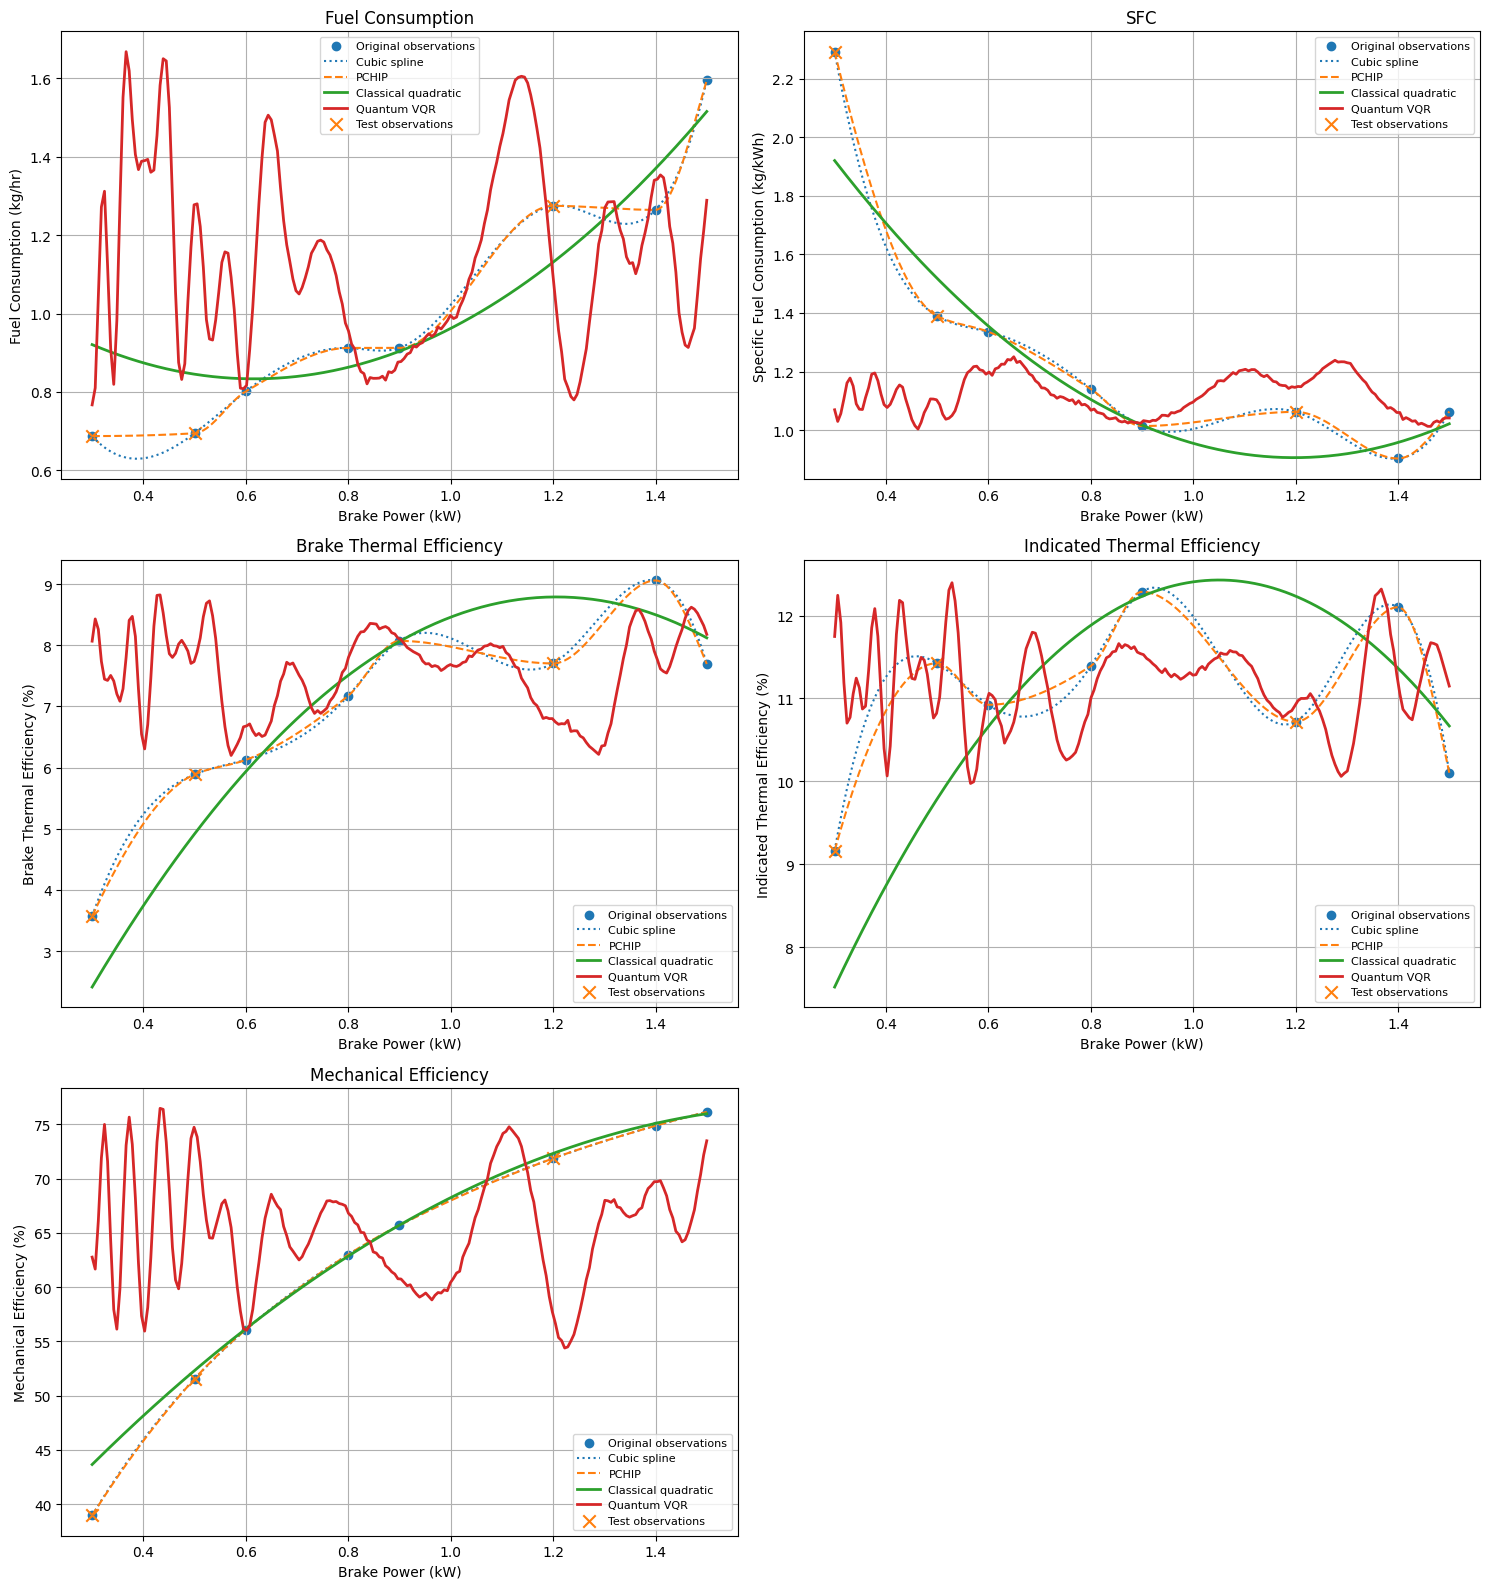


Saved:
1. engine_quantum_classical_metrics.csv
2. engine_performance_interpolation_vqr.png


In [3]:

# ============================================================
# ENGINE PERFORMANCE: INTERPOLATION + CLASSICAL REGRESSION + VQR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import CubicSpline, PchipInterpolator

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms import VQR

# ============================================================
# 1. ORIGINAL EXPERIMENTAL DATA
# ============================================================

voltage = np.array([200] * 9, dtype=float)

current = np.array([
    0, 1.5, 2.5, 3.0, 4.0, 4.5, 6.0, 7.0, 7.5
], dtype=float)

time = np.array([
    39.34, 38.75, 38.35, 33.24, 29.20,
    29.20, 20.90, 21.07, 16.70
], dtype=float)

# ============================================================
# 2. ENGINE CONSTANTS
# ============================================================

FP = 0.47                 # Friction power, kW
density = 0.74             # Fuel density, kg/L
fuel_volume_ml = 10        # Fuel volume, mL
CV = 44000                 # Calorific value, kJ/kg

fuel_mass = fuel_volume_ml / 1000 * density

# ============================================================
# 3. CALCULATE ENGINE PERFORMANCE PARAMETERS
# ============================================================

df = pd.DataFrame({
    "Voltage": voltage,
    "Current": current,
    "Time": time
})

# Retained from the original program.
# Verify this formula against the actual test-rig measurements.
df["Brake Power"] = df["Voltage"] * df["Current"] / 1000

df["Fuel Consumption"] = fuel_mass * 3600 / df["Time"]

fuel_rate = df["Fuel Consumption"] / 3600

df["Indicated Power"] = df["Brake Power"] + FP

df["SFC"] = np.where(
    df["Brake Power"] > 0,
    df["Fuel Consumption"] / df["Brake Power"],
    np.nan
)

df["Brake Thermal Efficiency"] = (
    df["Brake Power"] / (fuel_rate * CV) * 100
)

df["Indicated Thermal Efficiency"] = (
    df["Indicated Power"] / (fuel_rate * CV) * 100
)

df["Mechanical Efficiency"] = (
    df["Brake Power"] / df["Indicated Power"] * 100
)

# Remove the zero-brake-power observation because SFC is undefined.
df = df[df["Brake Power"] > 0].copy()
df.reset_index(drop=True, inplace=True)

targets = {
    "Fuel Consumption": "Fuel Consumption (kg/hr)",
    "SFC": "Specific Fuel Consumption (kg/kWh)",
    "Brake Thermal Efficiency": "Brake Thermal Efficiency (%)",
    "Indicated Thermal Efficiency": "Indicated Thermal Efficiency (%)",
    "Mechanical Efficiency": "Mechanical Efficiency (%)"
}

print("\nORIGINAL PERFORMANCE DATA")
print(df[["Brake Power"] + list(targets)].round(4).to_string(index=False))

# ============================================================
# 4. INTERPOLATION
# ============================================================

# Interpolation is for visualization only.
# It is NOT used to create extra training observations.

bp_original = df["Brake Power"].to_numpy()
bp_dense = np.linspace(bp_original.min(), bp_original.max(), 200)

interpolated = {}

for target in targets:
    y_original = df[target].to_numpy()

    # Cubic spline: smooth curve through the original points.
    cubic = CubicSpline(bp_original, y_original)
    y_cubic = cubic(bp_dense)

    # PCHIP: shape-preserving alternative.
    pchip = PchipInterpolator(bp_original, y_original)
    y_pchip = pchip(bp_dense)

    interpolated[target] = {
        "cubic": y_cubic,
        "pchip": y_pchip
    }

# ============================================================
# 5. SAME TRAIN/TEST SPLIT FOR BOTH MODELS
# ============================================================

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=3,
    random_state=42
)

bp = bp_original.reshape(-1, 1)
bp_train = bp[train_idx]
bp_test = bp[test_idx]

print("\nTraining observations:", len(train_idx))
print("Test observations:", len(test_idx))

# ============================================================
# 6. QUANTUM INPUT ENCODING
# ============================================================

# Scale input using training observations only.
x_scaler = MinMaxScaler(feature_range=(-1, 1))

x_train = x_scaler.fit_transform(bp_train).ravel()
x_test = x_scaler.transform(bp_test).ravel()
x_dense = x_scaler.transform(bp_dense.reshape(-1, 1)).ravel()

def quantum_features(x):
    """Encode one input using two classical features."""
    x = np.asarray(x).reshape(-1)

    return np.column_stack([
        x,
        2 * x**2 - 1
    ])

Xq_train = quantum_features(x_train)
Xq_test = quantum_features(x_test)
Xq_dense = quantum_features(x_dense)

# ============================================================
# 7. FIT CLASSICAL QUADRATIC REGRESSION AND QUANTUM VQR
# ============================================================

results = []
predictions = {}

for target, ylabel in targets.items():

    y = df[target].to_numpy()
    y_train = y[train_idx]
    y_test = y[test_idx]

    print("\n" + "=" * 60)
    print("PERFORMANCE PARAMETER:", target)
    print("=" * 60)

    # --------------------------------------------------------
    # A. CLASSICAL QUADRATIC REGRESSION
    # --------------------------------------------------------

    poly = PolynomialFeatures(degree=2, include_bias=False)

    X_train_poly = poly.fit_transform(bp_train)
    X_test_poly = poly.transform(bp_test)
    X_dense_poly = poly.transform(bp_dense.reshape(-1, 1))

    classical = LinearRegression()
    classical.fit(X_train_poly, y_train)

    pred_classical = classical.predict(X_test_poly)
    curve_classical = classical.predict(X_dense_poly)

    print(
        "Classical equation: y = "
        f"{classical.intercept_:.6f} "
        f"+ ({classical.coef_[0]:.6f}) BP "
        f"+ ({classical.coef_[1]:.6f}) BP^2"
    )

    # --------------------------------------------------------
    # B. NORMALIZE TARGET FOR VQR
    # --------------------------------------------------------

    y_scaler = MinMaxScaler(feature_range=(-0.8, 0.8))

    y_train_scaled = y_scaler.fit_transform(
        y_train.reshape(-1, 1)
    ).ravel()

    # --------------------------------------------------------
    # C. BUILD THE VARIATIONAL QUANTUM REGRESSOR
    # --------------------------------------------------------

    feature_map = ZZFeatureMap(
        feature_dimension=2,
        reps=1
    )

    ansatz = RealAmplitudes(
        num_qubits=2,
        reps=1
    )

    estimator = StatevectorEstimator()

    quantum = VQR(
        feature_map=feature_map,
        ansatz=ansatz,
        estimator=estimator,
        optimizer=COBYLA(maxiter=60)
    )

    quantum.fit(Xq_train, y_train_scaled)

    # Predictions are rescaled back into physical units.
    pred_q_scaled = np.asarray(
        quantum.predict(Xq_test)
    ).reshape(-1, 1)

    pred_quantum = y_scaler.inverse_transform(
        pred_q_scaled
    ).ravel()

    curve_q_scaled = np.asarray(
        quantum.predict(Xq_dense)
    ).reshape(-1, 1)

    curve_quantum = y_scaler.inverse_transform(
        curve_q_scaled
    ).ravel()

    # --------------------------------------------------------
    # D. EVALUATE BOTH MODELS ON THE SAME TEST OBSERVATIONS
    # --------------------------------------------------------

    for model_name, pred in [
        ("Classical Quadratic", pred_classical),
        ("Quantum VQR", pred_quantum)
    ]:

        r2 = r2_score(y_test, pred)
        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))

        results.append({
            "Parameter": target,
            "Model": model_name,
            "Test R2": r2,
            "Test MAE": mae,
            "Test RMSE": rmse
        })

        print(
            f"{model_name:22s} | "
            f"R2 = {r2:.4f} | "
            f"MAE = {mae:.4f} | "
            f"RMSE = {rmse:.4f}"
        )

    predictions[target] = {
        "actual": y_test,
        "bp_test": bp_test.ravel(),
        "classical_test": pred_classical,
        "quantum_test": pred_quantum,
        "classical_curve": curve_classical,
        "quantum_curve": curve_quantum,
        "classical_model": classical,
        "quantum_model": quantum,
        "y_scaler": y_scaler
    }

# ============================================================
# 8. METRICS TABLE AND CSV OUTPUT
# ============================================================

results_df = pd.DataFrame(results)

print("\nFINAL TEST-SET COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "engine_quantum_classical_metrics.csv",
    index=False
)

# ============================================================
# 9. ACTUAL VS PREDICTED VALUES
# ============================================================

for target in targets:

    p = predictions[target]

    comparison = pd.DataFrame({
        "Brake Power (kW)": p["bp_test"],
        "Actual": p["actual"],
        "Classical Prediction": p["classical_test"],
        "Quantum VQR Prediction": p["quantum_test"]
    })

    print("\nPREDICTIONS:", target)
    print(comparison.round(4).to_string(index=False))

# ============================================================
# 10. PLOT ALL FIVE PERFORMANCE CURVES
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes = axes.ravel()

for i, (target, ylabel) in enumerate(targets.items()):

    ax = axes[i]
    p = predictions[target]

    # Original measurements
    ax.scatter(
        bp_original,
        df[target].to_numpy(),
        label="Original observations",
        marker="o"
    )

    # Interpolation curves, using original observations
    ax.plot(
        bp_dense,
        interpolated[target]["cubic"],
        linestyle=":",
        label="Cubic spline"
    )

    ax.plot(
        bp_dense,
        interpolated[target]["pchip"],
        linestyle="--",
        label="PCHIP"
    )

    # Classical and quantum regression curves
    ax.plot(
        bp_dense,
        p["classical_curve"],
        label="Classical quadratic",
        linewidth=2
    )

    ax.plot(
        bp_dense,
        p["quantum_curve"],
        label="Quantum VQR",
        linewidth=2
    )

    # Mark the held-out test observations
    ax.scatter(
        p["bp_test"],
        p["actual"],
        marker="x",
        s=80,
        label="Test observations"
    )

    ax.set_xlabel("Brake Power (kW)")
    ax.set_ylabel(ylabel)
    ax.set_title(target)
    ax.grid(True)
    ax.legend(fontsize=8)

fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig(
    "engine_performance_interpolation_vqr.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved:")
print("1. engine_quantum_classical_metrics.csv")
print("2. engine_performance_interpolation_vqr.png")


# Welcome to Colab!

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) or [Colab Features You May Have Missed](https://www.youtube.com/watch?v=rNgswRZ2C1Y) to learn more, or just get started below!

<div class="markdown-google-sans">

## **Getting started**
</div>

The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code.

For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

## Google Colab is available in VS Code!
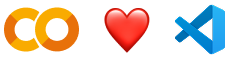

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

## Access popular AI models via Google-Colab-AI Without an API Key
All users have access to most popular LLMs via the `google-colab-ai` Python library, and paid users have access to a wider selection of models. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code, and audio.

**How to get started?**
*  Go to [Google AI Studio](https://aistudio.google.com/) and log in with your Google account.
*  [Create an API key](https://aistudio.google.com/app/apikey).
* Use a quickstart for [Python](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb), or call the REST API using [curl](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb).

**Discover Gemini's advanced capabilities**
*  Play with Gemini [multimodal outputs](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb), mixing text and images in an iterative way.
*  Discover the [multimodal Live API](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb ) (demo [here](https://aistudio.google.com/live)).
*  Learn how to [analyze images and detect items in your pictures](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb") using Gemini (bonus, there's a [3D version](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb) as well!).
*  Unlock the power of [Gemini thinking model](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb), capable of solving complex task with its inner thoughts.
      
**Explore complex use cases**
*  Use [Gemini grounding capabilities](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb) to create a report on a company based on what the model can find on internet.
*  Extract [invoices and form data from PDF](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb) in a structured way.
*  Create [illustrations based on a whole book](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb) using Gemini large context window and Imagen.

To learn more, check out the [Gemini cookbook](https://github.com/google-gemini/cookbook) or visit the [Gemini API documentation](https://ai.google.dev/docs/).


Colab now has AI features powered by [Gemini](https://gemini.google.com). The video below provides information on how to use these features, whether you're new to Python, or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  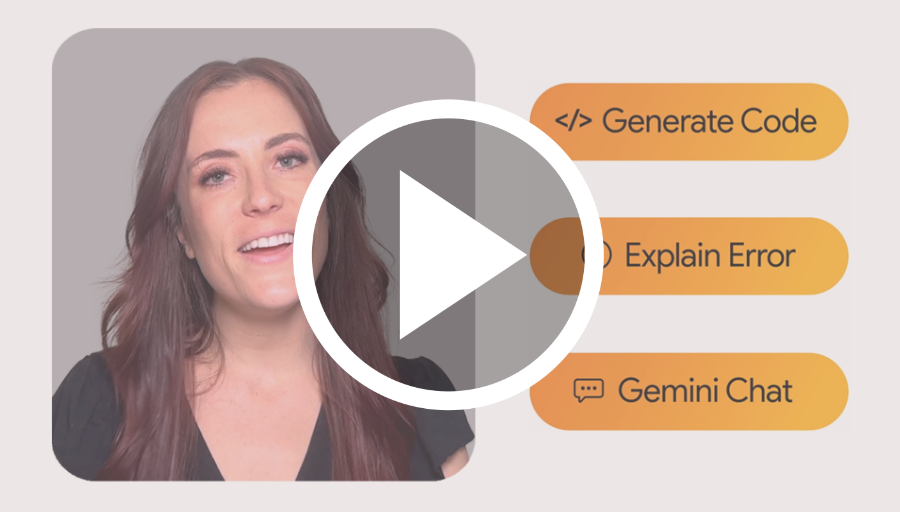
  </a>
</center>

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyze and visualize data. The code cell below uses **numpy** to generate some random data, and uses **matplotlib** to visualize it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from Github and many other sources. To learn more about importing data, and how Colab can be used for data science, see the links below under [Working with Data](#working-with-data).

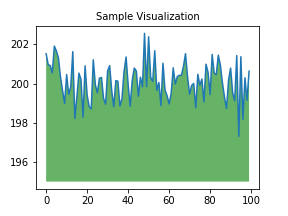

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning you can leverage the power of Google hardware, including [GPUs and TPUs](#using-accelerated-hardware), regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for **pandas** code to finish running and want to go faster, you can switch to a GPU Runtime and use libraries like [RAPIDS cuDF](https://rapids.ai/cudf-pandas) that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the [10 minute guide](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb) or
 [US stock market data analysis demo](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb).

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it, and evaluate the model, all in just [a few lines of code](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb).

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the [machine learning examples](#machine-learning-examples) below.

<div class="markdown-google-sans">

## More Resources

### Working with Notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with Data
</div>

- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine Learning

<div>

These are a few of the notebooks related to Machine Learning, including Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
